<a href="https://colab.research.google.com/github/SeoulTechPSE/tong_lectures/blob/main/4_fields_particles/standard_model/sm_ch06_figures.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

*The Standard Model* — `sm_ch06_figures.ipynb` · after D. Tong's Cambridge lecture notes · Kee-Youn Yoo, Process Systems Laboratory, SeoulTech

# Standard Model Ch 6 Figures — Colab Notebook
**The Standard Model · Chapter 6: Flavour**

Tong (DAMTP, Cambridge) · Run each cell to generate figures.
Output: `figures/ch06/fig0N_*.png`

| Figure | Section | Content |
|--------|---------|--------|
| fig01  | §6.1–6.2 | CKM matrix: magnitude table, Wolfenstein parametrisation, unitarity triangle |
| fig02  | §6.3     | Neutral kaon mixing: $K^0$-$\bar K^0$ oscillation, mass eigenstates $K_L$/$K_S$, box diagram |
| fig03  | §6.4     | CP violation: direct vs indirect, $\varepsilon$/$\varepsilon'$, $B$-factory measurements |

## Setup — dark palette & output directory

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.patheffects as pe
from matplotlib.patches import FancyArrowPatch, Circle, FancyBboxPatch, Arc, Wedge
from matplotlib.lines import Line2D
import os

# ── Dark palette (Standard Model series — teal/cyan accent) ───────────────
BG     = '#1e1e2e'
FG     = '#cdd6f4'
EDGE   = '#45475a'
TEAL   = '#2ec4b6'
BLUE   = '#7ec8e3'
YELLOW = '#f9c74f'
GREEN  = '#90ee90'
RED    = '#e07070'
PURPLE = '#c792ea'
ORANGE = '#e8a838'

plt.rcParams.update({
    'figure.facecolor'   : BG,
    'axes.facecolor'     : BG,
    'text.color'         : FG,
    'axes.labelcolor'    : FG,
    'xtick.color'        : FG,
    'ytick.color'        : FG,
    'axes.edgecolor'     : EDGE,
    'grid.color'         : EDGE,
    'grid.alpha'         : 0.3,
    'font.size'          : 12,
    'axes.titlesize'     : 13,
    'axes.titleweight'   : 'bold',
    'axes.titlecolor'    : TEAL,
    'legend.framealpha'  : 0.3,
    'legend.edgecolor'   : EDGE,
    'xtick.major.size'   : 4,
    'ytick.major.size'   : 4,
    'xtick.minor.visible': True,
    'ytick.minor.visible': True,
    'axes.linewidth'     : 1.2,
    'lines.linewidth'    : 2.2,
    'figure.dpi'         : 110,
})

OUTDIR = 'figures/ch06'
os.makedirs(OUTDIR, exist_ok=True)

def save(name, fig=None):
    f = fig or plt.gcf()
    path = f'{OUTDIR}/{name}'
    f.savefig(path, dpi=180, bbox_inches='tight', facecolor=BG)
    print(f'  saved -> {path}')
    plt.show()

print('Setup complete. Palette and output directory ready.')

Setup complete. Palette and output directory ready.


---
## fig01 · CKM Matrix and Unitarity Triangle (§6.1–6.2)

**Left**: $|V_{ij}|$ magnitude matrix — colour-coded heat map with PDG values  
**Middle**: Wolfenstein parametrisation structure — hierarchy in $\lambda\approx0.225$  
**Right**: Unitarity triangle in the $\bar\rho$-$\bar\eta$ plane with experimental constraints

beta=22.5° gamma=65.4° alpha=92.1°
  saved -> figures/ch06/fig01_ckm_triangle.png


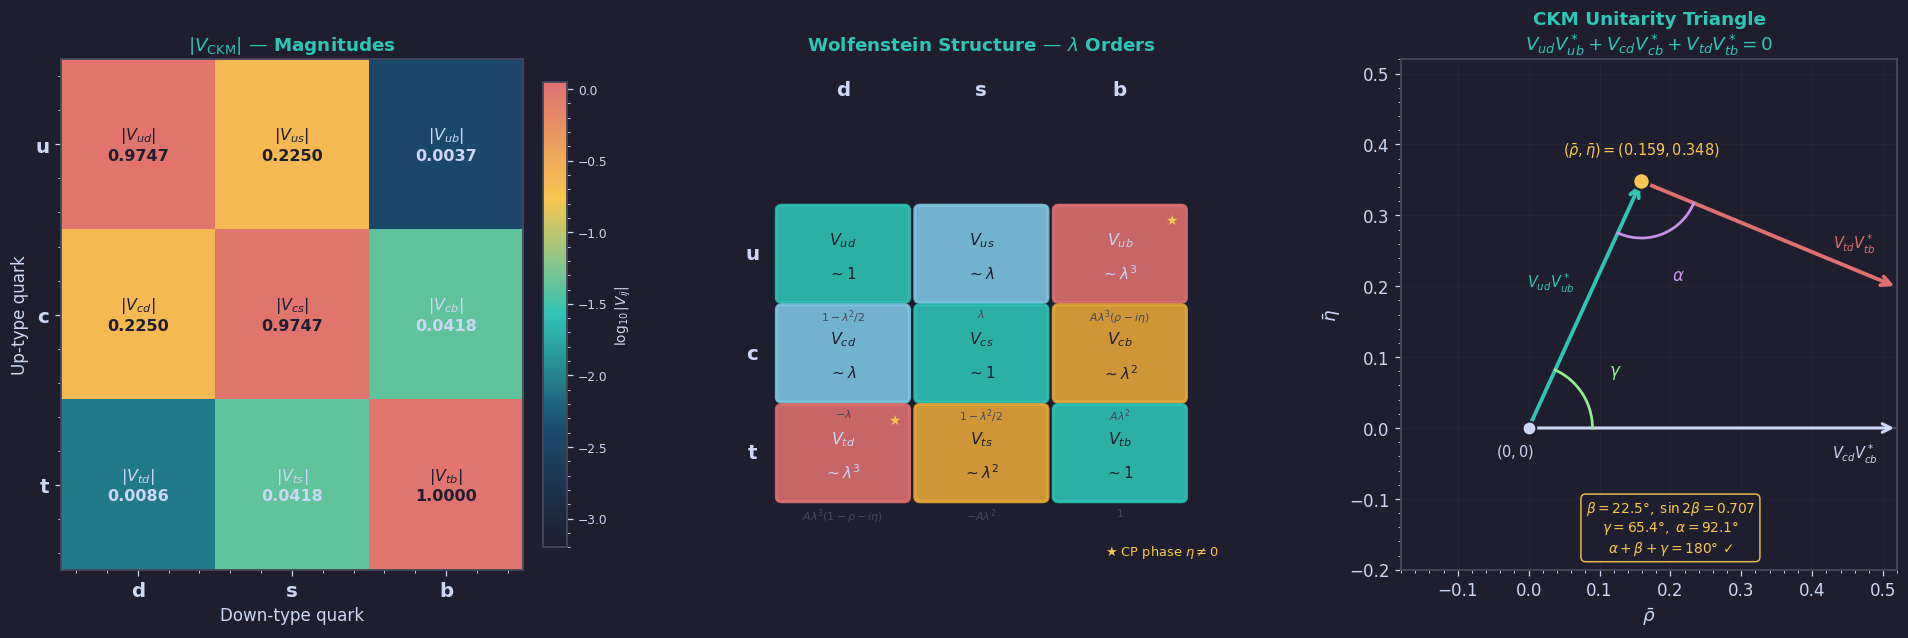

In [2]:
"""fig01_ckm_triangle.py
Left : |V_ij| heat map
Middle: Wolfenstein λ-order structure
Right : Unitarity triangle in (ρ̄, η̄) plane
"""
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch
from matplotlib.colors import LinearSegmentedColormap

BG='#1e1e2e'; FG='#cdd6f4'; EDGE='#45475a'
TEAL='#2ec4b6'; BLUE='#7ec8e3'; YELLOW='#f9c74f'
GREEN='#90ee90'; RED='#e07070'; ORANGE='#e8a838'; PURPLE='#c792ea'

plt.rcParams.update({
    'figure.facecolor':BG,'axes.facecolor':BG,'text.color':FG,
    'axes.labelcolor':FG,'xtick.color':FG,'ytick.color':FG,
    'axes.edgecolor':EDGE,'font.size':11,'axes.titlesize':12,
    'axes.titleweight':'bold','axes.titlecolor':TEAL,
})

# ── Wolfenstein 파라미터 (PDG 2022) ──────────────────────────────────────
lam   = 0.22500
A     = 0.826
rho_b = 0.159    # ρ̄
eta_b = 0.348    # η̄
rho   = rho_b / (1 - lam**2/2)
eta   = eta_b / (1 - lam**2/2)

# CKM 원소
Vud = 1 - lam**2/2
Vus = lam
Vub = A*lam**3*complex(rho, -eta)
Vcd = -lam
Vcs = 1 - lam**2/2
Vcb = A*lam**2
Vtd = A*lam**3*complex(1-rho, -eta)
Vts = -A*lam**2
Vtb = 1.0

V_abs = np.array([
    [abs(Vud), abs(Vus), abs(Vub)],
    [abs(Vcd), abs(Vcs), abs(Vcb)],
    [abs(Vtd), abs(Vts), abs(Vtb)],
])

labels_row = ['u', 'c', 't']
labels_col = ['d', 's', 'b']

fig, axes = plt.subplots(1, 3, figsize=(18, 5.8))
fig.patch.set_facecolor(BG)
plt.subplots_adjust(left=0.04, right=0.97, top=0.88, bottom=0.08, wspace=0.32)

# ═══════════════════════════════════════════════════════════════════════════
# 왼쪽: |V_ij| 히트맵
# ═══════════════════════════════════════════════════════════════════════════
ax = axes[0]
ax.set_facecolor(BG)

# 로그 스케일 컬러맵
log_vals = np.log10(V_abs + 1e-10)
cmap = LinearSegmentedColormap.from_list('ckm',
    [BG, '#1a4a6e', TEAL, YELLOW, RED])
im = ax.imshow(log_vals, cmap=cmap, vmin=-3.2, vmax=0.05,
               aspect='auto', interpolation='nearest')

# 셀 텍스트
for i in range(3):
    for j in range(3):
        val = V_abs[i, j]
        txt = f'$|V_{{{labels_row[i]}{labels_col[j]}}}|$\n{val:.4f}'
        bg_col = '#ffffff' if log_vals[i,j] > -1.0 else FG
        ax.text(j, i, txt, ha='center', va='center',
                color=BG if log_vals[i,j] > -0.8 else FG,
                fontsize=10.5, fontweight='bold',
                bbox=dict(boxstyle='round,pad=0.15', fc='none', ec='none'))

ax.set_xticks([0,1,2]); ax.set_xticklabels(['d','s','b'], fontsize=13, fontweight='bold')
ax.set_yticks([0,1,2]); ax.set_yticklabels(['u','c','t'], fontsize=13, fontweight='bold', rotation=0)
ax.set_xlabel('Down-type quark', fontsize=11)
ax.set_ylabel('Up-type quark', fontsize=11)
ax.set_title(r'$|V_{\rm CKM}|$ — Magnitudes', fontsize=12, color=TEAL)

cbar = plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
cbar.set_label(r'$\log_{10}|V_{ij}|$', color=FG, fontsize=9)
cbar.ax.yaxis.set_tick_params(color=FG)
plt.setp(cbar.ax.yaxis.get_ticklabels(), color=FG, fontsize=8)

# ═══════════════════════════════════════════════════════════════════════════
# 가운데: Wolfenstein λ 차수 구조
# ═══════════════════════════════════════════════════════════════════════════
ax2 = axes[1]
ax2.set_facecolor(BG)
ax2.set_xlim(-0.4, 3.4)
ax2.set_ylim(-0.6, 3.6)
ax2.axis('off')
ax2.set_title(r'Wolfenstein Structure — $\lambda$ Orders', fontsize=12, color=TEAL)

# 셀 크기
CW, CH = 0.92, 0.72
GAP_X, GAP_Y = 0.12, 0.10

# (i,j) → (x,y) 변환: i=행(위→아래), j=열(왼→오른)
def cell_xy(i, j):
    x = j * (CW + GAP_X)
    y = (2 - i) * (CH + GAP_Y)  # 행 0이 위
    return x, y

cell_data = [
    # (row, col, label_top, order_str, col_bg, col_text, tooltip)
    (0, 0, r'$V_{ud}$', r'$\sim 1$',           TEAL,   BG,     r'$1-\lambda^2/2$'),
    (0, 1, r'$V_{us}$', r'$\sim\lambda$',       BLUE,   BG,     r'$\lambda$'),
    (0, 2, r'$V_{ub}$', r'$\sim\lambda^3$',     RED,    FG,     r'$A\lambda^3(\rho-i\eta)$'),
    (1, 0, r'$V_{cd}$', r'$\sim\lambda$',       BLUE,   BG,     r'$-\lambda$'),
    (1, 1, r'$V_{cs}$', r'$\sim 1$',            TEAL,   BG,     r'$1-\lambda^2/2$'),
    (1, 2, r'$V_{cb}$', r'$\sim\lambda^2$',     ORANGE, BG,     r'$A\lambda^2$'),
    (2, 0, r'$V_{td}$', r'$\sim\lambda^3$',     RED,    FG,     r'$A\lambda^3(1-\rho-i\eta)$'),
    (2, 1, r'$V_{ts}$', r'$\sim\lambda^2$',     ORANGE, BG,     r'$-A\lambda^2$'),
    (2, 2, r'$V_{tb}$', r'$\sim 1$',            TEAL,   BG,     r'$1$'),
]

# 행/열 헤더
for j, lbl in enumerate(['d','s','b']):
    x, _ = cell_xy(0, j)
    ax2.text(x + CW/2, 3.35, lbl,
             ha='center', va='center', color=FG, fontsize=13, fontweight='bold')
for i, lbl in enumerate(['u','c','t']):
    _, y = cell_xy(i, 0)
    ax2.text(-0.22, y + CH/2, lbl,
             ha='center', va='center', color=FG, fontsize=13, fontweight='bold')

for row, col, lbl, order, cbg, ctxt, expr in cell_data:
    x, y = cell_xy(row, col)
    rect = FancyBboxPatch((x, y), CW, CH,
                          boxstyle='round,pad=0.04',
                          edgecolor=cbg if ctxt==BG else cbg,
                          facecolor=cbg, lw=2.0, alpha=0.88)
    ax2.add_patch(rect)
    # 원소 이름 (위쪽)
    ax2.text(x + CW/2, y + CH*0.66, lbl,
             ha='center', va='center', color=ctxt, fontsize=10.5, fontweight='bold')
    # λ 차수 (아래쪽, 더 크게)
    ax2.text(x + CW/2, y + CH*0.28, order,
             ha='center', va='center', color=ctxt, fontsize=10)
    # Wolfenstein 표현식 (셀 아래 작게)
    ax2.text(x + CW/2, y - 0.08, expr,
             ha='center', va='top', color=EDGE, fontsize=7.2)

# CP 위반 셀 (Vub, Vtd) 표시
for row, col in [(0,2),(2,0)]:
    x, y = cell_xy(row, col)
    ax2.text(x + CW - 0.03, y + CH - 0.03, '★',
             ha='right', va='top', color=YELLOW, fontsize=9)
ax2.text(3.28, -0.45, '★ CP phase $\\eta\\neq0$',
         ha='right', va='center', color=YELLOW, fontsize=8.5)

# ═══════════════════════════════════════════════════════════════════════════
# 오른쪽: 유니타리 삼각형
# ═══════════════════════════════════════════════════════════════════════════
ax3 = axes[2]
ax3.set_facecolor(BG)

# 꼭짓점: O=(0,0), C=(1,0), A=(rho_b, eta_b)
O = np.array([0.0, 0.0])
C = np.array([1.0, 0.0])
A = np.array([rho_b, eta_b])

# 각도 계산
beta  = np.arctan2(eta_b, 1 - rho_b)
gamma = np.arctan2(eta_b, rho_b)
alpha = np.pi - beta - gamma
print(f'beta={np.degrees(beta):.1f}° gamma={np.degrees(gamma):.1f}° alpha={np.degrees(alpha):.1f}°')

# 불확도 영역: 각 꼭짓점 불확도
sig_rho = 0.010; sig_eta = 0.009
theta_ell = np.linspace(0, 2*np.pi, 200)
ell_x = rho_b + sig_rho * np.cos(theta_ell)
ell_y = eta_b + sig_eta * np.sin(theta_ell)
ax3.fill(ell_x, ell_y, color=YELLOW, alpha=0.25, zorder=4)

# 삼각형 변 색상
ax3.plot([O[0],C[0]], [O[1],C[1]], color=EDGE, lw=1.5, ls='--', zorder=2)

# V_cd V_cb* 변 (기준, 회색)
# ax3.annotate('', xy=C, xytext=O,
ax3.annotate('', xy=(0.52,0), xytext=O,
    arrowprops=dict(arrowstyle='->', color=FG, lw=2.0, mutation_scale=14))

# V_ud V_ub* 변
ax3.annotate('', xy=A, xytext=O,
    arrowprops=dict(arrowstyle='->', color=TEAL, lw=2.5, mutation_scale=15))

# V_td V_tb* 변
# ax3.annotate('', xy=C, xytext=A,
#     arrowprops=dict(arrowstyle='->', color=RED, lw=2.5, mutation_scale=15))
x_end = 0.52
slope = (0.0 - A[1]) / (1.0 - A[0])
y_end = A[1] + slope * (x_end - A[0])

ax3.annotate('', xy=(x_end, y_end), xytext=A,
    arrowprops=dict(arrowstyle='->', color=RED, lw=2.5, mutation_scale=15))

# 꼭짓점 마커
ax3.scatter(*O, s=80, color=FG,     zorder=6, edgecolors=BG, lw=1.2)
# ax3.scatter(*C, s=80, color=FG,     zorder=6, edgecolors=BG, lw=1.2)
ax3.scatter(*A, s=120, color=YELLOW, zorder=7, edgecolors=BG, lw=1.5)

# 꼭짓점 레이블
ax3.text(O[0]-0.02, O[1]-0.02, r'$(0,0)$',
         ha='center', va='top', color=FG, fontsize=9.5)
# ax3.text(C[0]+0.03, C[1]-0.048, r'$(1,0)$',
#          ha='center', va='top', color=FG, fontsize=9.5)
ax3.text(A[0], A[1]+0.030, r'$(\bar\rho,\bar\eta)=(0.159,0.348)$',
         ha='center', va='bottom', color=YELLOW, fontsize=9.5,
         fontweight='bold')

# 변 레이블 (중간점에)
mid_OA = (O + A) / 2
mid_AC = (A + C) / 2
mid_OC = (O + C) / 2

# ax3.text(mid_OA[0]-0.045, mid_OA[1]+0.015,
#          r'$V_{ud}V_{ub}^*$', ha='right', va='bottom',
#          color=TEAL, fontsize=9.5, fontweight='bold')
ax3.text(mid_OA[0]-0.015, mid_OA[1]+0.015,
         r'$V_{ud}V_{ub}^*$', ha='right', va='bottom',
         color=TEAL, fontsize=9.5, fontweight='bold')
# ax3.text(mid_AC[0]+0.025, mid_AC[1]+0.015,
#          r'$V_{td}V_{tb}^*$', ha='left', va='bottom',
#          color=RED, fontsize=9.5, fontweight='bold')
ax3.text(0.43, mid_AC[1]+0.07,
         r'$V_{td}V_{tb}^*$', ha='left', va='bottom',
         color=RED, fontsize=9.5, fontweight='bold')
# ax3.text(mid_OC[0], mid_OC[1]-0.040,
#          r'$V_{cd}V_{cb}^*$', ha='center', va='top',
#          color=FG, fontsize=9.5)
ax3.text(0.46, mid_OC[1]-0.020,
         r'$V_{cd}V_{cb}^*$', ha='center', va='top',
         color=FG, fontsize=9.5)

# 각도 호와 레이블
def angle_arc(ax, vertex, p1, p2, radius, color, label, label_offset):
    """꼭짓점에서 p1, p2 방향의 각도 호 그리기"""
    a1 = np.arctan2(p1[1]-vertex[1], p1[0]-vertex[0])
    a2 = np.arctan2(p2[1]-vertex[1], p2[0]-vertex[0])
    if a2 < a1: a1, a2 = a2, a1
    # 호의 올바른 방향 선택 (작은 쪽)
    if a2 - a1 > np.pi: a1, a2 = a2, a1+2*np.pi
    t = np.linspace(a1, a2, 60)
    ax.plot(vertex[0] + radius*np.cos(t),
            vertex[1] + radius*np.sin(t),
            color=color, lw=1.8, zorder=5)
    mid_t = (a1+a2)/2
    lx = vertex[0] + (radius+label_offset)*np.cos(mid_t)
    ly = vertex[1] + (radius+label_offset)*np.sin(mid_t)
    ax.text(lx, ly, label, ha='center', va='center',
            color=color, fontsize=11, fontweight='bold')

angle_arc(ax3, O, C, A, 0.09, GREEN, r'$\gamma$', 0.055)
# angle_arc(ax3, C, O, A, 0.09, ORANGE, r'$\beta$', 0.058)
angle_arc(ax3, A, O, C, 0.08, PURPLE, r'$\alpha$', 0.062)

# 수치 요약 박스
summary = (
    f'$\\beta = {np.degrees(beta):.1f}°,\\;'
    f'\\sin 2\\beta = {np.sin(2*beta):.3f}$\n'
    f'$\\gamma = {np.degrees(gamma):.1f}°,\\;'
    f'\\alpha = {np.degrees(alpha):.1f}°$\n'
    r'$\alpha+\beta+\gamma = 180°$ ✓'
)
ax3.text(0.2, -0.10, summary,
         ha='center', va='top', color=YELLOW, fontsize=9,
         bbox=dict(boxstyle='round,pad=0.35', fc=BG, ec=YELLOW, alpha=0.9))

ax3.set_xlabel(r'$\bar\rho$', fontsize=12)
ax3.set_ylabel(r'$\bar\eta$', fontsize=12)
ax3.set_title('CKM Unitarity Triangle\n'
              r'$V_{ud}V_{ub}^* + V_{cd}V_{cb}^* + V_{td}V_{tb}^* = 0$',
              fontsize=12, color=TEAL)
ax3.set_xlim(-0.18, 0.52)
ax3.set_ylim(-0.20, 0.52)
ax3.set_aspect('equal')
ax3.grid(True, alpha=0.15)

save('fig01_ckm_triangle.png', fig)

# 새 섹션

---
## fig02 · Neutral Kaon Mixing (§6.3)

**Left**: $K^0$-$\bar K^0$ box diagram — $W$ exchange with up-type quarks in the loop  
**Middle**: Mass eigenstates $K_L$/$K_S$ — mixing matrix and CP properties  
**Right**: $K_S$/$K_L$ time evolution — oscillation of strangeness and exponential decay

  saved -> figures/ch06/fig02_kaon_mixing.png


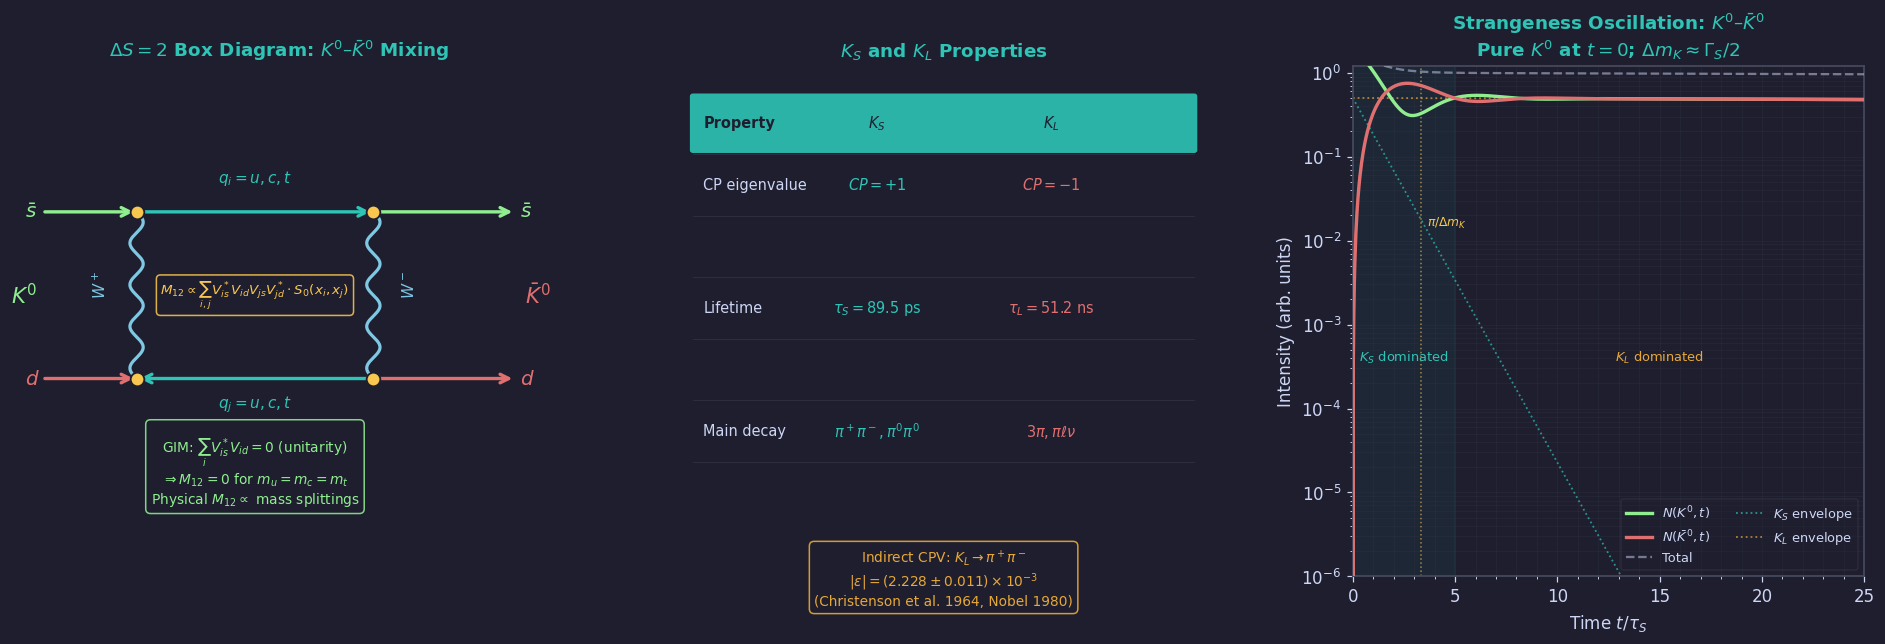

In [3]:
"""fig02_kaon_mixing.py
Left : ΔS=2 박스 다이어그램 (Feynman)
Middle: K_L / K_S 성질 비교 표
Right : 이상도(strangeness) 진동 곡선
"""
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

BG='#1e1e2e'; FG='#cdd6f4'; EDGE='#45475a'
TEAL='#2ec4b6'; BLUE='#7ec8e3'; YELLOW='#f9c74f'
GREEN='#90ee90'; RED='#e07070'; ORANGE='#e8a838'; PURPLE='#c792ea'

plt.rcParams.update({
    'figure.facecolor':BG,'axes.facecolor':BG,'text.color':FG,
    'axes.labelcolor':FG,'xtick.color':FG,'ytick.color':FG,
    'axes.edgecolor':EDGE,'font.size':11,'axes.titlesize':12,
    'axes.titleweight':'bold','axes.titlecolor':TEAL,
})

fig, axes = plt.subplots(1, 3, figsize=(18, 5.8))
fig.patch.set_facecolor(BG)
plt.subplots_adjust(left=0.04, right=0.97, top=0.88, bottom=0.08, wspace=0.30)

# ═══════════════════════════════════════════════════════════════════════════
# 왼쪽: ΔS=2 박스 다이어그램
# ═══════════════════════════════════════════════════════════════════════════
ax = axes[0]
ax.set_facecolor(BG); ax.axis('off')
ax.set_xlim(-0.2, 5.2); ax.set_ylim(-0.5, 4.4)
ax.set_title(r'$\Delta S=2$ Box Diagram: $K^0$–$\bar K^0$ Mixing',
             fontsize=12, color=TEAL)

def wavy(ax, x1,y1,x2,y2, col=BLUE, n=5, amp=0.055, lw=2.1):
    t=np.linspace(0,1,300)
    ang=np.arctan2(y2-y1,x2-x1); L=np.hypot(x2-x1,y2-y1)
    s=t*L; p=amp*np.sin(2*np.pi*n*t)
    ax.plot(x1+s*np.cos(ang)-p*np.sin(ang),
            y1+s*np.sin(ang)+p*np.cos(ang), color=col, lw=lw, zorder=4)

def farr(ax, x1,y1,x2,y2, col, lw=2.0, ms=14):
    ax.annotate('', xy=(x2,y2), xytext=(x1,y1),
        arrowprops=dict(arrowstyle='->', color=col, lw=lw, mutation_scale=ms))

def vdot(ax, x, y, col=YELLOW, s=80):
    ax.scatter([x],[y], s=s, color=col, zorder=7, edgecolors=BG, lw=1.2)

# 박스 꼭짓점
x1,y1 = 1.0, 3.0   # 왼위
x2,y2 = 3.5, 3.0   # 오른위
x3,y3 = 3.5, 1.4   # 오른아래
x4,y4 = 1.0, 1.4   # 왼아래

# 쿼크 라인 (K0 → 위쪽, K0bar → 아래쪽)
# K0: d̄s → 위 변을 d̄, s̄ 방향으로
farr(ax, 0.0, 3.0, x1, 3.0, GREEN, lw=2.2)   # s̄ incoming
farr(ax, 0.0, 1.4, x4, 1.4, RED,   lw=2.2)   # d  incoming
farr(ax, x2, 3.0, 5.0, 3.0, GREEN, lw=2.2)   # s̄ outgoing (K̄0)
farr(ax, x3, 1.4, 5.0, 1.4, RED,   lw=2.2)   # d  outgoing

# 쿼크 내부 (u,c,t 루프)
farr(ax, x1,y1, x2,y2, TEAL, lw=2.2)   # 위 쿼크 (좌→우)
farr(ax, x3,y3, x4,y4, TEAL, lw=2.2)   # 아래 쿼크 (우→좌)

# W 보손 (세로)
wavy(ax, x1,y1, x4,y4, col=BLUE, n=4, amp=0.07)  # 왼 W
wavy(ax, x2,y2, x3,y3, col=BLUE, n=4, amp=0.07)  # 오른 W

# 꼭짓점 점
for x,y in [(x1,y1),(x2,y2),(x3,y3),(x4,y4)]:
    vdot(ax, x, y, YELLOW)

# 레이블
ax.text(-0.18, 3.0,  r'$\bar s$', color=GREEN,  fontsize=13, va='center', fontweight='bold')
ax.text(-0.18, 1.4,  r'$d$',      color=RED,    fontsize=13, va='center', fontweight='bold')
ax.text(5.05,  3.0,  r'$\bar s$', color=GREEN,  fontsize=13, va='center', fontweight='bold')
ax.text(5.05,  1.4,  r'$d$',      color=RED,    fontsize=13, va='center', fontweight='bold')

# 루프 쿼크 레이블 (박스 내부 중앙)
ax.text(2.25, 3.28, r'$q_i=u,c,t$', color=TEAL, fontsize=10, ha='center')
ax.text(2.25, 1.12, r'$q_j=u,c,t$', color=TEAL, fontsize=10, ha='center')
# W 레이블
ax.text(0.62, 2.20, r'$W^+$', color=BLUE, fontsize=10, ha='center', rotation=90)
ax.text(3.88, 2.20, r'$W^-$', color=BLUE, fontsize=10, ha='center', rotation=90)

# CKM 버텍스 레이블 (작게)
for (xx,yy,lbl) in [(x1,y1,r'$V_{is}^*V_{id}$'),(x2,y2,r'$V_{js}V_{jd}^*$'),
                     (x4,y4,r'$V_{is}^*V_{id}$'),(x3,y3,r'$V_{js}V_{jd}^*$')]:
    pass  # 너무 복잡해서 생략

# K0, K0bar 레이블
ax.text(-0.05, 2.20, r'$K^0$',       color=GREEN,  fontsize=14,
        ha='right', va='center', fontweight='bold')
ax.text(5.10,  2.20, r'$\bar K^0$',  color=RED,    fontsize=14,
        ha='left',  va='center', fontweight='bold')

# 중앙 M12 레이블
ax.text(2.25, 2.20, r'$M_{12}\propto\sum_{i,j}V_{is}^*V_{id}V_{js}V_{jd}^*\cdot S_0(x_i,x_j)$',
        ha='center', va='center', color=YELLOW, fontsize=8.8,
        bbox=dict(boxstyle='round,pad=0.3', fc=BG, ec=YELLOW, alpha=0.88))

# GIM 메커니즘 설명 박스
ax.text(2.25, 0.50,
        r'GIM: $\sum_i V_{is}^*V_{id}=0$ (unitarity)' + '\n'
        r'$\Rightarrow M_{12}=0$ for $m_u=m_c=m_t$' + '\n'
        r'Physical $M_{12}\propto$ mass splittings',
        ha='center', va='center', color=GREEN, fontsize=9,
        bbox=dict(boxstyle='round,pad=0.35', fc=BG, ec=GREEN, alpha=0.88))

# ═══════════════════════════════════════════════════════════════════════════
# 가운데: K_L / K_S 성질 표
# ═══════════════════════════════════════════════════════════════════════════
ax2 = axes[1]
ax2.set_facecolor(BG); ax2.axis('off')
ax2.set_xlim(0, 5); ax2.set_ylim(-0.3, 5.5)
ax2.set_title(r'$K_S$ and $K_L$ Properties', fontsize=12, color=TEAL)

# 균등 간격 계산
# 헤더 + 6개 행 → 7개 행 총 높이 내에 균등 배분
TOTAL_H = 4.9
N_ROWS  = 7
ROW_H   = TOTAL_H / N_ROWS
Y_TOP   = 5.2   # 헤더 상단

def draw_row(ax, y_center, cells, cols, bold_mask=None, bg=None):
    """cells: list of (text, col_idx, ha), cols: x positions for each col"""
    if bg:
        rect = FancyBboxPatch((0.05, y_center - ROW_H*0.44), 4.90, ROW_H*0.88,
                               boxstyle='round,pad=0.03',
                               facecolor=bg, edgecolor='none', alpha=0.18)
        ax.add_patch(rect)
    for txt, ci, ha, color in cells:
        weight = 'bold' if (bold_mask and bold_mask[ci]) else 'normal'
        ax.text(cols[ci], y_center, txt, ha=ha, va='center',
                color=color, fontsize=10, fontweight=weight)

cols_x   = [0.15, 1.85, 3.55]
col_ha   = ['left','center','center']
hdr_cols = [FG, TEAL, RED]

rows = [
    # (property, KS_val, KL_val)
    ('Property',            r'$K_S$',           r'$K_L$'),
    ('CP eigenvalue',       r'$CP=+1$',         r'$CP=-1$'),
    ('Quark content\n(approx.)',
                            r'$\frac{K^0+\bar K^0}{\sqrt{2}}$',
                            r'$\frac{K^0-\bar K^0}{\sqrt{2}}$'),
    ('Lifetime',            r'$\tau_S=89.5$ ps', r'$\tau_L=51.2$ ns'),
    (r'$\tau_L/\tau_S$',   r'—',               r'$\approx571$'),
    ('Main decay',          r'$\pi^+\pi^-,\pi^0\pi^0$',
                            r'$3\pi,\pi\ell\nu$'),
    (r'$\Delta m_K$',
     r'$m_L-m_S=3.484\times10^{-12}$ MeV',
     r'$\approx\Gamma_S/2$'),
]

bgs = [TEAL, None, TEAL, None, TEAL, None, TEAL]

# 헤더 배경
rect_hdr = FancyBboxPatch((0.05, Y_TOP - ROW_H*0.94), 4.90, ROW_H*0.88,
                           boxstyle='round,pad=0.03',
                           facecolor=TEAL, edgecolor='none', alpha=0.90, zorder=0)
ax2.add_patch(rect_hdr)

for i, (prop, ks, kl) in enumerate(rows):
    y_c   = Y_TOP - (i + 0.5) * ROW_H
    bg    = bgs[i]
    color0 = BG if bg else FG
    color1 = BG if bg else TEAL
    color2 = BG if bg else RED
    if i == 0:
        color0 = BG; color1 = BG; color2 = BG

    # 구분선
    if i > 0:
        ax2.axhline(Y_TOP - i*ROW_H, color=EDGE, lw=0.5, alpha=0.5,
                    xmin=0.01, xmax=0.99)

    ax2.text(cols_x[0], y_c, prop, ha='left', va='center',
             color=color0, fontsize=9.5,
             fontweight='bold' if i==0 else 'normal')
    ax2.text(cols_x[1], y_c, ks, ha='center', va='center',
             color=color1, fontsize=9.5,
             fontweight='bold' if i==0 else 'normal')
    ax2.text(cols_x[2], y_c, kl, ha='center', va='center',
             color=color2, fontsize=9.5,
             fontweight='bold' if i==0 else 'normal')

# ε 박스
y_eps = Y_TOP - N_ROWS*ROW_H - 0.28
ax2.text(2.50, y_eps,
         r'Indirect CPV: $K_L\to\pi^+\pi^-$' + '\n'
         r'$|\varepsilon|=(2.228\pm0.011)\times10^{-3}$' + '\n'
         r'(Christenson et al. 1964, Nobel 1980)',
         ha='center', va='top', color=ORANGE, fontsize=9,
         bbox=dict(boxstyle='round,pad=0.35', fc=BG, ec=ORANGE, alpha=0.90))

# ═══════════════════════════════════════════════════════════════════════════
# 오른쪽: 이상도 진동
# ═══════════════════════════════════════════════════════════════════════════
ax3 = axes[2]
ax3.set_facecolor(BG)

# 파라미터 (PDG 2022)
tau_S  = 89.54e-12    # s
tau_L  = 51.16e-9     # s
hbar   = 1.0          # 단위: ℏ=1로 정규화
DeltaM = 3.484e-12 * 1e-3 / (6.582e-22)  # MeV → rad/s … 그냥 비율로
# 시간축: tau_S 단위
t_max  = 25           # in units of tau_S
t      = np.linspace(0, t_max * tau_S, 2000)

# Δm_K / Γ_S ≈ 0.948 (실험)
DmGS   = 0.948
tau_S_norm = 1.0   # 정규화 단위
tau_L_norm = tau_L / tau_S   # ≈ 571

# 시간축: tau_S 단위
tt = np.linspace(0, t_max, 1000)

# 진폭: ψ(t) = a_S e^{-iM_S t} e^{-Γ_S t/2} + a_L e^{-iM_L t} e^{-Γ_L t/2}
GS  = 1.0                     # Γ_S = 1 (정규화)
GL  = GS / (tau_L / tau_S)    # Γ_L
DM  = DmGS * GS               # Δm

# K0 생성 (strangeness +1 상태): aS=1/sqrt2, aL=1/sqrt2
# N(K0, t)  ~ e^{-GS t} + e^{-GL t} + 2 cos(DM t) e^{-(GS+GL)t/2}
# N(K0bar,t)~ e^{-GS t} + e^{-GL t} - 2 cos(DM t) e^{-(GS+GL)t/2}
N_K0     = 0.5*(np.exp(-GS*tt) + np.exp(-GL*tt) + 2*np.cos(DM*tt)*np.exp(-(GS+GL)*tt/2))
N_K0bar  = 0.5*(np.exp(-GS*tt) + np.exp(-GL*tt) - 2*np.cos(DM*tt)*np.exp(-(GS+GL)*tt/2))
N_total  = N_K0 + N_K0bar
# 비대칭
asym = (N_K0 - N_K0bar) / (N_K0 + N_K0bar + 1e-12)

ax3.semilogy(tt, N_K0,    color=GREEN,  lw=2.2, label=r'$N(K^0,t)$',    zorder=4)
ax3.semilogy(tt, N_K0bar, color=RED,    lw=2.2, label=r'$N(\bar K^0,t)$', zorder=4)
ax3.semilogy(tt, N_total, color=FG,     lw=1.5, ls='--', alpha=0.5,
             label='Total', zorder=3)

# K_S 감쇠 가이드
ax3.semilogy(tt, 0.5*np.exp(-GS*tt), color=TEAL, lw=1.2, ls=':', alpha=0.7,
             label=r'$K_S$ envelope')
ax3.semilogy(tt, 0.5*np.exp(-GL*tt), color=ORANGE, lw=1.2, ls=':', alpha=0.7,
             label=r'$K_L$ envelope')

# 진동 표시 영역 (K_S가 살아있는 초반)
ax3.axvspan(0, 5, color=TEAL, alpha=0.06, zorder=1)
ax3.text(2.5, 5e-4, r'$K_S$ dominated', color=TEAL, fontsize=8.5,
         ha='center', va='top')
ax3.text(15, 5e-4, r'$K_L$ dominated', color=ORANGE, fontsize=8.5,
         ha='center', va='top')

# Δm 표시
ax3.axvline(np.pi/DM, color=YELLOW, lw=1.0, ls=':', alpha=0.6)
ax3.text(np.pi/DM + 0.3, 0.02, r'$\pi/\Delta m_K$', color=YELLOW, fontsize=8, va='top')

ax3.set_xlabel(r'Time $t/\tau_S$', fontsize=11)
ax3.set_ylabel('Intensity (arb. units)', fontsize=11)
ax3.set_title(r'Strangeness Oscillation: $K^0$–$\bar K^0$' + '\n'
              r'Pure $K^0$ at $t=0$; $\Delta m_K\approx\Gamma_S/2$',
              fontsize=12, color=TEAL)
ax3.set_xlim(0, t_max)
ax3.set_ylim(1e-6, 1.2)
ax3.legend(fontsize=8.5, labelcolor=FG, loc='lower right',
           facecolor=BG, edgecolor=EDGE, ncol=2)
ax3.grid(True, alpha=0.15, which='both')
ax3.tick_params(which='both', colors=FG)
for sp in ax3.spines.values(): sp.set_edgecolor(EDGE)

save('fig02_kaon_mixing.png', fig)

---
## fig03 · CP Violation (§6.4)

**Left**: Direct vs indirect CP violation — $\varepsilon$ (mixing) and $\varepsilon'$ (decay)  
**Middle**: $B$-factory measurements — $\sin 2\beta$ from $B^0\to J/\psi K_S$ time-dependent asymmetry  
**Right**: CKM fit global constraints — all measurements consistent with one $\delta_{CP}$

  saved -> figures/ch06/fig03_cp_violation.png


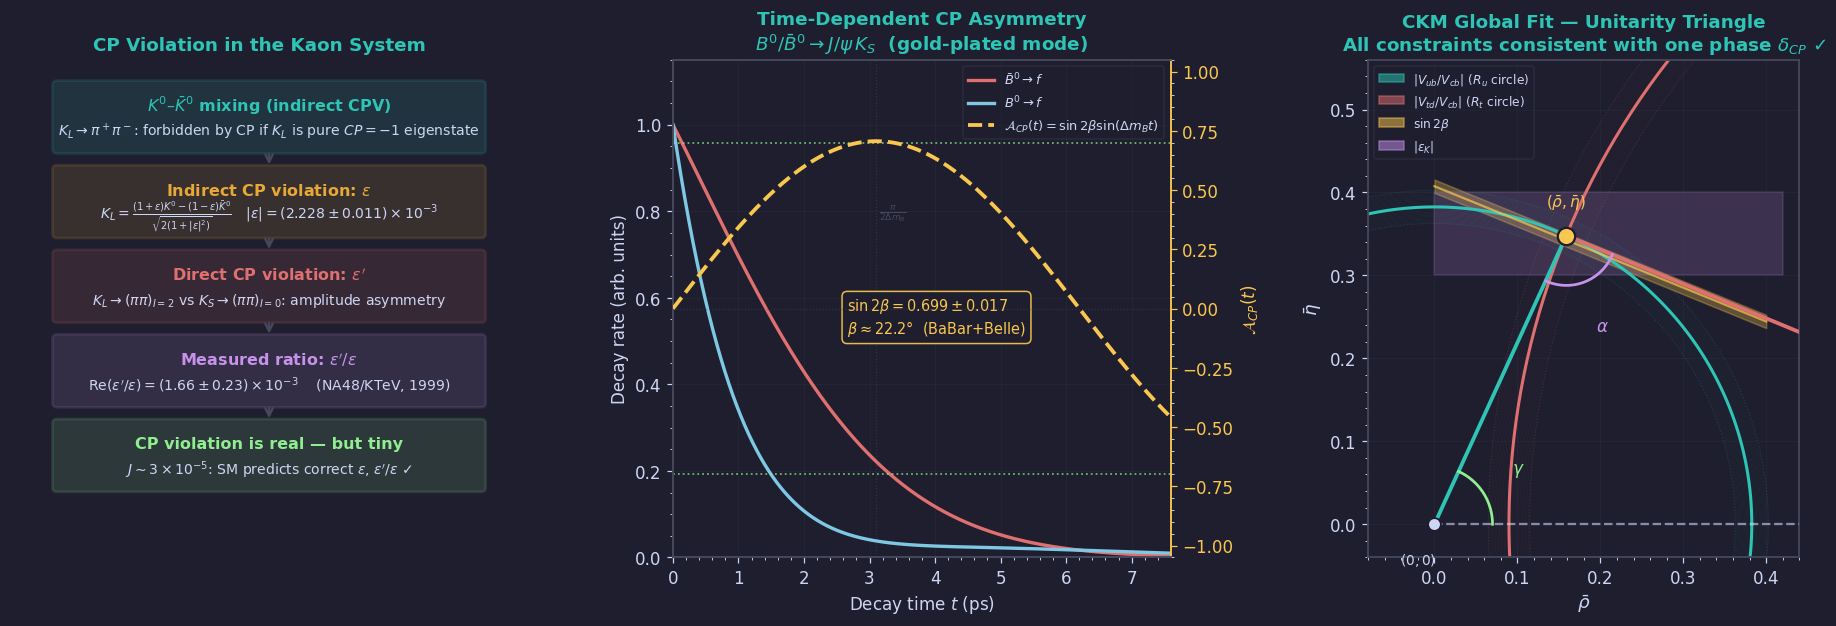

In [4]:
"""fig03_cp_violation.py
Left : ε, ε' in kaon system (schematic)
Middle: sin2β time-dependent CP asymmetry (B→J/ψ K_S)
Right : CKM global fit — unitarity triangle constraints
"""
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, Ellipse, Arc
import matplotlib.patches as mpatches

BG='#1e1e2e'; FG='#cdd6f4'; EDGE='#45475a'
TEAL='#2ec4b6'; BLUE='#7ec8e3'; YELLOW='#f9c74f'
GREEN='#90ee90'; RED='#e07070'; ORANGE='#e8a838'; PURPLE='#c792ea'

plt.rcParams.update({
    'figure.facecolor':BG,'axes.facecolor':BG,'text.color':FG,
    'axes.labelcolor':FG,'xtick.color':FG,'ytick.color':FG,
    'axes.edgecolor':EDGE,'font.size':11,'axes.titlesize':12,
    'axes.titleweight':'bold','axes.titlecolor':TEAL,
})

fig, axes = plt.subplots(1, 3, figsize=(18, 5.8))
fig.patch.set_facecolor(BG)
plt.subplots_adjust(left=0.05, right=0.97, top=0.88, bottom=0.10, wspace=0.33)

lam=0.22500; A=0.826; rho_b=0.159; eta_b=0.348
beta  = np.arctan2(eta_b, 1-rho_b)
sin2b = np.sin(2*beta)

# ═══════════════════════════════════════════════════════════════════════════
# 왼쪽: ε, ε' — 카온계 CP 위반 계층
# ═══════════════════════════════════════════════════════════════════════════
ax = axes[0]
ax.set_facecolor(BG); ax.axis('off')
ax.set_xlim(-0.2, 5.2); ax.set_ylim(-0.4, 5.6)
ax.set_title(r'CP Violation in the Kaon System', fontsize=12, color=TEAL)

# 박스들을 균등 간격으로 배치
# 총 5개 레벨, ylim [−0.4, 5.6] 사용 가능 높이 5.4
# 상하 여백 0.3씩 → 사용 가능 4.8 / 5칸

BOX_W = 4.6; BOX_H = 0.78
GAP   = 0.24
Y_TOP = 5.30

def fbox(ax, yc, title, body, color, fs_title=10.5, fs_body=9.2):
    rect = FancyBboxPatch((0.3, yc - BOX_H/2), BOX_W, BOX_H,
                           boxstyle='round,pad=0.05', lw=1.8,
                           edgecolor=color, facecolor=color, alpha=0.13)
    ax.add_patch(rect)
    ax.text(0.3 + BOX_W/2, yc + BOX_H*0.18, title,
            ha='center', va='center', color=color,
            fontsize=fs_title, fontweight='bold')
    if body:
        ax.text(0.3 + BOX_W/2, yc - BOX_H*0.22, body,
                ha='center', va='center', color=FG, fontsize=fs_body)

def farr_v(ax, y1, y2, col):
    mid_x = 0.3 + BOX_W/2
    ax.annotate('', xy=(mid_x, y2 + BOX_H/2 + 0.02),
                    xytext=(mid_x, y1 - BOX_H/2 - 0.02),
                arrowprops=dict(arrowstyle='->', color=col, lw=1.6, mutation_scale=12))

boxes = [
    # (yc, title, body, color)
    (Y_TOP - 0*(BOX_H+GAP) - BOX_H/2,
     r'$K^0$–$\bar K^0$ mixing (indirect CPV)',
     r'$K_L\to\pi^+\pi^-$: forbidden by CP if $K_L$ is pure $CP=-1$ eigenstate',
     TEAL),
    (Y_TOP - 1*(BOX_H+GAP) - BOX_H/2,
     r'Indirect CP violation: $\varepsilon$',
     r'$K_L = \frac{(1+\varepsilon)K^0-(1-\varepsilon)\bar K^0}{\sqrt{2(1+|\varepsilon|^2)}}$'
     r'$\quad|\varepsilon|=(2.228\pm0.011)\times10^{-3}$',
     ORANGE),
    (Y_TOP - 2*(BOX_H+GAP) - BOX_H/2,
     r'Direct CP violation: $\varepsilon^\prime$',
     r'$K_L\to(\pi\pi)_{I=2}$ vs $K_S\to(\pi\pi)_{I=0}$: amplitude asymmetry',
     RED),
    (Y_TOP - 3*(BOX_H+GAP) - BOX_H/2,
     r'Measured ratio: $\varepsilon^\prime/\varepsilon$',
     r'$\mathrm{Re}(\varepsilon^\prime/\varepsilon)=(1.66\pm0.23)\times10^{-3}$'
     r'$\quad$ (NA48/KTeV, 1999)',
     PURPLE),
    (Y_TOP - 4*(BOX_H+GAP) - BOX_H/2,
     'CP violation is real — but tiny',
     r'$J\sim3\times10^{-5}$: SM predicts correct $\varepsilon$, $\varepsilon^\prime/\varepsilon$ ✓',
     GREEN),
]

for yc, title, body, col in boxes:
    fbox(ax, yc, title, body, col)

# 화살표 연결
for i in range(len(boxes)-1):
    y1 = boxes[i][0]; y2 = boxes[i+1][0]
    farr_v(ax, y1, y2, EDGE)

# ═══════════════════════════════════════════════════════════════════════════
# 가운데: sin2β — 시간의존 CP 비대칭 (B→J/ψ K_S)
# ═══════════════════════════════════════════════════════════════════════════
ax2 = axes[1]
ax2.set_facecolor(BG)

# 파라미터
DmB  = 0.5065   # ps^-1
tauB = 1.519    # ps (B0 lifetime, PDG 2022)
sin2b_exp = 0.699   # BaBar+Belle average

t    = np.linspace(0, 5*tauB, 500)   # ps
GammaB = 1 / tauB

# B̄0 생성 후 B0→f, B̄0→f 붕괴율
# 올바른 부호 (PDG 관례: A_CP = [Γ(B̄→f) - Γ(B→f)] / 합)
# = +sin2β sin(Δm t)   for b→ccs̄ (J/ψ K_S)
N_Bbar_to_f = np.exp(-GammaB*t) * (1 + sin2b * np.sin(DmB*t))
N_B_to_f    = np.exp(-GammaB*t) * (1 - sin2b * np.sin(DmB*t))
asym        = sin2b * np.sin(DmB * t)   # 진정한 비대칭

ax2.plot(t, N_Bbar_to_f / N_Bbar_to_f[0], color=RED,  lw=2.2,
         label=r'$\bar B^0\to f$', zorder=4)
ax2.plot(t, N_B_to_f    / N_Bbar_to_f[0], color=BLUE, lw=2.2,
         label=r'$B^0\to f$',      zorder=4)

ax2_twin = ax2.twinx()
ax2_twin.set_facecolor(BG)
ax2_twin.plot(t, asym, color=YELLOW, lw=2.5, ls='--',
              label=r'$\mathcal{A}_{CP}(t)=\sin2\beta\sin(\Delta m_B t)$',
              zorder=5)
ax2_twin.axhline(0, color=EDGE, lw=0.8, ls=':', alpha=0.5)
ax2_twin.axhline( sin2b_exp, color=GREEN, lw=1.2, ls=':', alpha=0.7)
ax2_twin.axhline(-sin2b_exp, color=GREEN, lw=1.2, ls=':', alpha=0.7)
ax2_twin.set_ylim(-1.05, 1.05)
ax2_twin.set_ylabel(r'$\mathcal{A}_{CP}(t)$', color=YELLOW, fontsize=11)
ax2_twin.tick_params(axis='y', colors=YELLOW)
ax2_twin.spines['right'].set_edgecolor(YELLOW)

# 진동 주기 표시
period = 2*np.pi / DmB
ax2.axvline(period/4, color=EDGE, lw=0.8, ls=':', alpha=0.5)
ax2.text(period/4 + 0.05, 0.82, r'$\frac{\pi}{2\Delta m_B}$',
         color=EDGE, fontsize=8.5, va='top')

# sin2β 결과 박스
ax2.text(0.35, 0.44,
         r'$\sin 2\beta = 0.699\pm0.017$' + '\n'
         r'$\beta\approx22.2°$  (BaBar+Belle)',
         transform=ax2.transAxes,
         ha='left', va='bottom', color=YELLOW, fontsize=9.5,
         bbox=dict(boxstyle='round,pad=0.35', fc=BG, ec=YELLOW, alpha=0.92))

ax2.set_xlabel(r'Decay time $t$ (ps)', fontsize=11)
ax2.set_ylabel(r'Decay rate (arb. units)', fontsize=11)
ax2.set_title(r'Time-Dependent CP Asymmetry' + '\n'
              r'$B^0/\bar B^0\to J/\psi\, K_S$  (gold-plated mode)',
              fontsize=12, color=TEAL)
ax2.set_xlim(0, 5*tauB)
ax2.set_ylim(0, 1.15)

# 범례 합치기
lines1, labs1 = ax2.get_legend_handles_labels()
lines2, labs2 = ax2_twin.get_legend_handles_labels()
ax2.legend(lines1+lines2, labs1+labs2, fontsize=8.5, labelcolor=FG,
           loc='upper right', facecolor=BG, edgecolor=EDGE)
ax2.grid(True, alpha=0.15)
for sp in ax2.spines.values(): sp.set_edgecolor(EDGE)
ax2_twin.spines['top'].set_edgecolor(EDGE)
ax2_twin.spines['bottom'].set_edgecolor(EDGE)
ax2_twin.spines['left'].set_edgecolor(EDGE)

# ═══════════════════════════════════════════════════════════════════════════
# 오른쪽: CKM 전역 맞춤 — 유니타리 삼각형 제약
# ═══════════════════════════════════════════════════════════════════════════
ax3 = axes[2]
ax3.set_facecolor(BG)

rho_range = np.linspace(-0.1, 0.42, 400)
eta_range = np.linspace(0.0,  0.55, 400)

# 꼭짓점 & 삼각형
O = np.array([0.0, 0.0])
C = np.array([1.0, 0.0])
A = np.array([rho_b, eta_b])

# ── 각 관측량이 주는 제약 ──────────────────────────────────────────────
# 1. |Vub/Vcb| → R_u 원
Ru = np.sqrt(rho_b**2 + eta_b**2)
theta_circ = np.linspace(0, 2*np.pi, 300)
# 불확도 ±0.020
for dr, alpha_ in [(0.020, 0.15), (0.0, 1.0)]:
    ax3.plot(Ru*np.cos(theta_circ) if dr==0 else (Ru+dr)*np.cos(theta_circ),
             Ru*np.sin(theta_circ) if dr==0 else (Ru+dr)*np.sin(theta_circ),
             color=TEAL, lw=2.0 if dr==0 else 0.8, alpha=alpha_, ls='-' if dr==0 else ':')
    if dr > 0:
        ax3.plot((Ru-dr)*np.cos(theta_circ), (Ru-dr)*np.sin(theta_circ),
                 color=TEAL, lw=0.8, alpha=0.15, ls=':')
ax3.fill_between((Ru-0.020)*np.cos(theta_circ),
                 (Ru-0.020)*np.sin(theta_circ),
                 (Ru+0.020)*np.sin(theta_circ), alpha=0.0)
# 채우기: 원 밴드
rr_arr = np.linspace(Ru-0.020, Ru+0.020, 30)
for rr in rr_arr:
    ax3.plot(rr*np.cos(theta_circ), rr*np.sin(theta_circ),
             color=TEAL, lw=0.3, alpha=0.06)

# 2. |Vtd/Vcb| → R_t 원 (중심 (1,0))
Rt = np.sqrt((1-rho_b)**2 + eta_b**2)
for dr, alpha_ in [(0.025, 0.15), (0.0, 1.0)]:
    xc = np.cos(theta_circ) * (Rt if dr==0 else Rt+dr)
    yc = np.sin(theta_circ) * (Rt if dr==0 else Rt+dr)
    ax3.plot(1+xc, yc, color=RED, lw=2.0 if dr==0 else 0.8,
             alpha=alpha_, ls='-' if dr==0 else ':')
    if dr > 0:
        xc2 = (Rt-dr)*np.cos(theta_circ)
        yc2 = (Rt-dr)*np.sin(theta_circ)
        ax3.plot(1+xc2, yc2, color=RED, lw=0.8, alpha=0.15, ls=':')
# 채우기
for dr in np.linspace(-0.025, 0.025, 30):
    xc = (Rt+dr)*np.cos(theta_circ)
    yc = (Rt+dr)*np.sin(theta_circ)
    ax3.plot(1+xc, yc, color=RED, lw=0.3, alpha=0.06)

# 3. sin2β 제약: β = 일정 직선 (원점에서)
# β = arctan(η/(1-ρ)) → 직선 η = (1-ρ)tan(β)
beta_exp = np.arcsin(0.699)/2
rho_line = np.linspace(0, 0.40, 100)
eta_line = (1 - rho_line) * np.tan(beta_exp)
ax3.fill_between(rho_line, eta_line-0.008, eta_line+0.008,
                 color=YELLOW, alpha=0.30, label=r'$\sin2\beta$ (BaBar+Belle)')
ax3.plot(rho_line, eta_line, color=YELLOW, lw=1.5, alpha=0.7)

# 4. |ε_K| 제약: 쌍곡선 영역 (개략)
# |ε_K| ∝ η(ρ(1-ρ) - η²) ...
# 단순화: ε_K 제약은 η̄ > 0 영역의 아래쪽 경계
rho_ek = np.linspace(0.0, 0.42, 200)
# 경험적 근사: η = c / (A² λ^6 (1-ρ))  ...
ek_lo = 0.30 * np.ones_like(rho_ek)   # 하한
ek_hi = 0.40 * np.ones_like(rho_ek)   # 상한
ax3.fill_between(rho_ek, ek_lo, ek_hi,
                 color=PURPLE, alpha=0.18, label=r'$|\varepsilon_K|$')

# 삼각형
ax3.plot([O[0],A[0]], [O[1],A[1]], color=TEAL, lw=2.5, zorder=5)
ax3.plot([A[0],C[0]], [A[1],C[1]], color=RED,  lw=2.5, zorder=5)
# ax3.plot([O[0],C[0]], [O[1],C[1]], color=FG,   lw=1.5, ls='--', alpha=0.6, zorder=4)
ax3.plot([O[0],0.44], [O[1],0], color=FG,   lw=1.5, ls='--', alpha=0.6, zorder=4)

# 꼭짓점
ax3.scatter(*O, s=70, color=FG,     zorder=8, edgecolors=BG, lw=1.2)
# ax3.scatter(*C, s=70, color=FG,     zorder=8, edgecolors=BG, lw=1.2)
ax3.scatter(*A, s=130, color=YELLOW, zorder=9, edgecolors=BG, lw=1.5)

ax3.text(O[0]-0.02, O[1]-0.032, r'$(0,0)$',  ha='center', va='top',
         color=FG, fontsize=9)
# ax3.text(C[0]+0.02, C[1]-0.032, r'$(1,0)$',  ha='center', va='top',
#          color=FG, fontsize=9)
ax3.text(A[0],      A[1]+0.028, r'$(\bar\rho,\bar\eta)$',
         ha='center', va='bottom', color=YELLOW, fontsize=10, fontweight='bold')

# 각도 호
def arc_angle(ax, vertex, p1, p2, r, col, lbl, lbl_r):
    a1 = np.arctan2(p1[1]-vertex[1], p1[0]-vertex[0])
    a2 = np.arctan2(p2[1]-vertex[1], p2[0]-vertex[0])
    if a1 > a2: a1, a2 = a2, a1
    if a2 - a1 > np.pi: a1, a2 = a2, a1 + 2*np.pi
    tt = np.linspace(a1, a2, 80)
    ax.plot(vertex[0]+r*np.cos(tt), vertex[1]+r*np.sin(tt),
            color=col, lw=1.8, zorder=6)
    mid = (a1+a2)/2
    ax.text(vertex[0]+(r+lbl_r)*np.cos(mid),
            vertex[1]+(r+lbl_r)*np.sin(mid),
            lbl, ha='center', va='center',
            color=col, fontsize=11, fontweight='bold')

arc_angle(ax3, O, C, A, 0.07, GREEN,  r'$\gamma$', 0.050)
# arc_angle(ax3, C, O, A, 0.07, ORANGE, r'$\beta$',  0.055)
arc_angle(ax3, A, O, C, 0.06, PURPLE, r'$\alpha$', 0.058)

ax3.set_xlabel(r'$\bar\rho$', fontsize=12)
ax3.set_ylabel(r'$\bar\eta$', fontsize=12)
ax3.set_title(r'CKM Global Fit — Unitarity Triangle' + '\n'
              r'All constraints consistent with one phase $\delta_{CP}$ ✓',
              fontsize=12, color=TEAL)
ax3.set_xlim(-0.08, 0.44)
ax3.set_ylim(-0.04, 0.56)
ax3.set_aspect('equal')
ax3.grid(True, alpha=0.15)

# 범례
handles = [
    mpatches.Patch(color=TEAL,   alpha=0.5, label=r'$|V_{ub}/V_{cb}|$ ($R_u$ circle)'),
    mpatches.Patch(color=RED,    alpha=0.5, label=r'$|V_{td}/V_{cb}|$ ($R_t$ circle)'),
    mpatches.Patch(color=YELLOW, alpha=0.5, label=r'$\sin 2\beta$'),
    mpatches.Patch(color=PURPLE, alpha=0.5, label=r'$|\varepsilon_K|$'),
]
ax3.legend(handles=handles, fontsize=8, labelcolor=FG,
           loc='upper left', facecolor=BG, edgecolor=EDGE)

for sp in ax3.spines.values(): sp.set_edgecolor(EDGE)

save('fig03_cp_violation.png', fig)

In [5]:
import zipfile, os

ZIP_NAME = 'sm_ch06_figures.zip'
OUTDIR   = 'figures/ch06'

with zipfile.ZipFile(ZIP_NAME, 'w', compression=zipfile.ZIP_DEFLATED) as zf:
    for fname in sorted(os.listdir(OUTDIR)):
        if fname.endswith('.png'):
            fpath = os.path.join(OUTDIR, fname)
            zf.write(fpath, arcname=fname)
            print(f'  added: {fname}  ({os.path.getsize(fpath)//1024} KB)')

print(f'\nArchive ready: {ZIP_NAME}  ({os.path.getsize(ZIP_NAME)//1024} KB)')

try:
    from google.colab import files
    files.download(ZIP_NAME)
    print('Download started — check your browser.')
except ImportError:
    print(f'Not running in Colab.  Zip saved at: {os.path.abspath(ZIP_NAME)}')

  added: fig01_ckm_triangle.png  (196 KB)
  added: fig02_kaon_mixing.png  (210 KB)
  added: fig03_cp_violation.png  (411 KB)

Archive ready: sm_ch06_figures.zip  (773 KB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Download started — check your browser.


---
## All figures generated

| File | Used in slide |
|------|---------------|
| `figures/ch06/fig01_ckm_triangle.png` | §6.1–6.2 · CKM Matrix & Unitarity Triangle |
| `figures/ch06/fig02_kaon_mixing.png`  | §6.3 · Neutral Kaon Mixing |
| `figures/ch06/fig03_cp_violation.png` | §6.4 · CP Violation |

Copy the `figures/` folder next to `sm_ch06_slides.qmd` before rendering with Quarto.